# Introduction to clonal embeddings

This notebook walks through a complete clone2vec analysis of [in vitro hematopoiesis](https://www.science.org/doi/10.1126/science.aaw3381) data from Weinreb et al. Mouse hematopoietic progenitors were labelled with heritable barcodes and cultured. On day 2, part of the cells was sequenced and the rest was split between wells, which were sequenced on days 4 and 6. Every sequenced cell therefore has a **state** (its transcriptome) and a **history** (its barcode).

The goal is to describe each clone by *where its cells end up*, without relying on cell type labels, and then to see which clonal behaviours exist.

**The plan:**

1. Look at the data: what a single clone looks like.
2. Build a clone-level object (one row per clone).
3. Count which clones neighbour each other in expression space.
4. Compress these counts into a clonal embedding with clone2vec.
5. Explore clones like cells: UMAP, clustering, fate composition.
6. Bring the clonal clusters back to the cells.
7. Use the experimental design to ask whether sister clones behave alike.

## Setup

In [1]:
import scanpy as sc
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import clone2vec as c2v

sc.set_figure_params(dpi=80)
sc.settings.verbosity = 3
sns.set_style("ticks")

## Step 1: Look at the data

`adata` is a regular single-cell object: one row per cell, with cell type annotation, the time point and well, the clonal barcode in `adata.obs["Clone"]` (`"NA"` for cells without a barcode), and a SPRING layout in `adata.obsm["X_spring"]` for plotting.

In [2]:
adata = c2v.datasets.Weinreb_in_vitro()

Before building anything, let's look at what a clone actually is. On the left are the annotated cell types; on the right, the cells of one large clone coloured by the day they were sequenced.

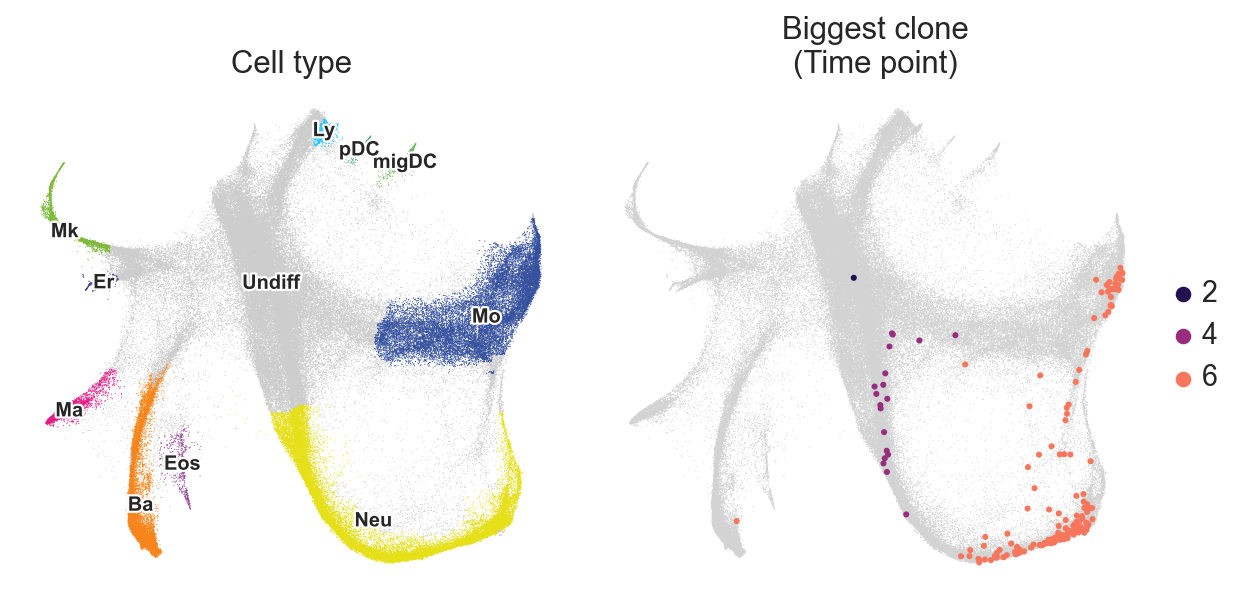

In [3]:
fig, axes = plt.subplots(ncols=2, figsize=(8, 4))

sc.pl.embedding(
    adata,
    basis="X_spring",
    color="Cell type annotation short",
    frameon=False,
    title="Cell type",
    legend_loc="on data",
    legend_fontsize=9,
    legend_fontoutline=2,
    ax=axes[0],
    show=False,
)

# This function makes possible to plot subparts of the embedding
# on top of the whole embedding
c2v.pl.group_scatter(
    adata,
    groupby="Clone",
    groups=adata.obs["Clone"].value_counts().index[1],
    basis="X_spring",
    title="Biggest clone",
    kwargs_group={"color": "Time point"},
    ax=axes[1],
)

fig.tight_layout()

**What to look for:** the clone is not a point but a *cloud*. Its day-4 cells sit in the undifferentiated region, and by day 6 its cells have spread into both the neutrophil (Neu) and monocyte (Mo) branches. This spread over the expression landscape is exactly what clone2vec describes.

Most clones are much smaller than this one, so for most of them we only see a few points of such a cloud.

## Step 2: One row per clone

clone2vec works with two objects side by side: `adata` (one row per cell) and `clones` (one row per clone).

**Which unit is a "clone" here?** In this experiment, cells sharing a barcode were split between time points and wells. Cells of the same barcode in different wells are sister populations that grew in different environments. We want to keep them apart, so that later (Step 7) we can ask whether sisters behave alike. So we define the clonal unit as the combination `time point : well : barcode`.

Two parameters of `c2v.pp.clones_adata` matter:

* `min_size=2` drops clones with a single cell. A one-cell clone tells us nothing about how its cells are *distributed*.
* `fill_obs` computes each clone's cell type composition. It is used **only to describe** clones afterwards. The embedding itself never sees cell types.

In [4]:
adata.obs["time:well:clone"] = (
    adata.obs["Time point"].astype(str) + ":" +
    adata.obs["Well"].astype(str) + ":" +
    adata.obs["Clone"].astype(str)
)

adata.obs["time:well:clone"] = [
    i if not i.endswith(":NA") else "NA"
    for i in adata.obs["time:well:clone"]
]

clones = c2v.pp.clones_adata(
    adata,
    obs_name="time:well:clone",
    min_size=2,
    na_value="NA",
    fill_obs="Cell type annotation short",
)

creating clone-level AnnData
    selected 8173 clones (>= 2)
    finished (0:00:00): created clones AnnData with
     .X float matrix of proportions (clones × categories)
     .layers['proportions'] float matrix with fate proportions
     .layers['counts'] integer matrix with fate counts
     .obs['n_cells'] integer vector with number of cells per clone
     .obs['n_fates'] integer vector with number of fates per clone
     .var['n_clones'] integer vector with number of clones per fate
     .uns['fill_obs'] string label


We get 8,173 clonal units. Let's see how big they are.

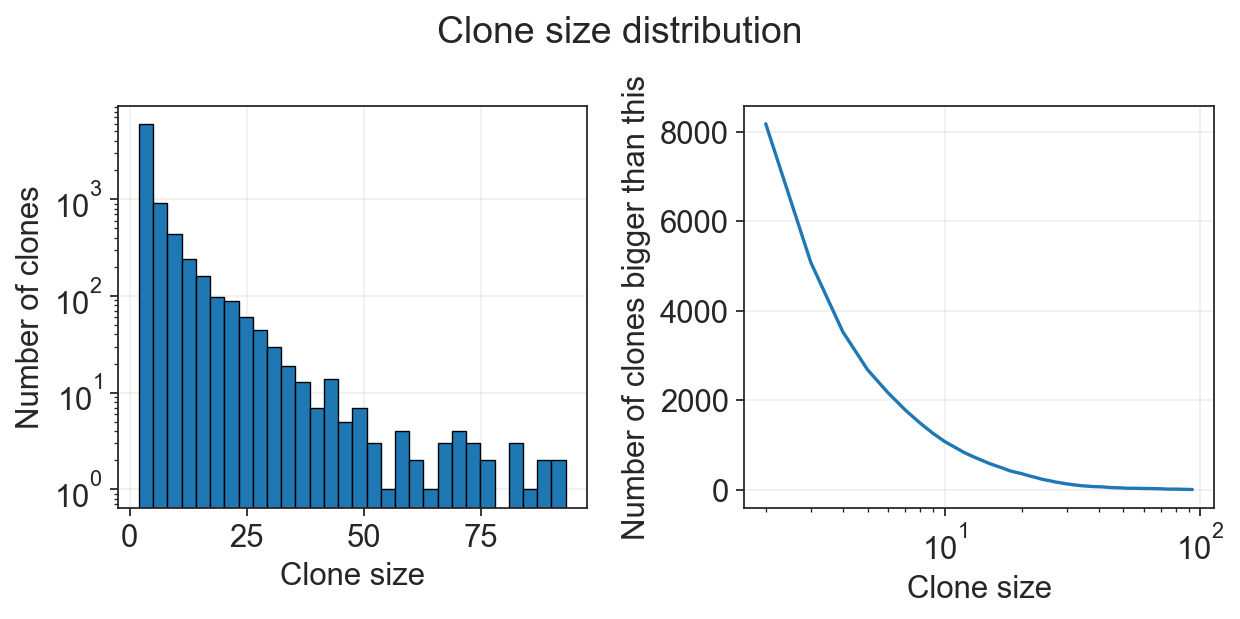

In [5]:
c2v.pl.clone_size(clones)

**What to look for:** note the log scale. Thousands of clones have just 2–5 cells, and only a handful have more than 50. This heavy-tailed size distribution is typical of lineage tracing data. Describing each clone on its own (for example by its cell type proportions) is very noisy for the small ones. clone2vec is designed to keep them anyway, because it learns from all clones jointly.

Next, we copy the time point, well and barcode of each clonal unit from the cells to the clones. We need them in Step 7. Transferred columns get the `gex_` prefix (`clones.obs["gex_Well"]`, ...).

In [6]:
c2v.pp.transfer_annotation(adata, clones, annotation_obs_adata=["Time point", "Well", "Clone"])

transferring annotations between cell and clone objects
    finished (0:00:00): added to clonal AnnData
     .obs['gex_Time point'] categorical labels
     .obs['gex_Well'] categorical labels
     .obs['gex_Clone'] categorical labels


## Step 3: Who neighbours whom

This is the core idea of clone2vec. Instead of describing a clone by its own cells, we describe it by **which clones its cells sit next to** in expression space:

1. For every barcoded cell, find its *k* nearest barcoded neighbours (`k=15` by default).
2. For every clone, count how many of its cells' neighbours belong to each clone, itself included.

The result is a clone × clone matrix of neighbour counts. Row *i* is the "neighbourhood profile" of clone *i*. Two clones of a similar behaviour have similar rows, even if their few cells never land in exactly the same place.

Why `use_rep="X_pca_harmony"`? The representation decides what "neighbour" means. If it still contained a batch effect, cells would mostly neighbour cells of their own batch, and clones would group by batch. So we use the batch-corrected PCA.

In [7]:
c2v.tl.clonal_nn(adata, clones, use_rep="X_pca_harmony")

computing clone-to-clone adjacency graph
    finished (0:00:48): added
     .obsp['gex_adjacency'] clone adjacency graph.
     .uns['clonal_nn'] parameters.


The matrix is stored as a sparse graph in `clones.obsp["gex_adjacency"]`.

## Step 4: The clonal embedding

`c2v.tl.clone2vec` compresses this matrix into a short vector per clone (10 dimensions by default). It trains a Skip-Gram model, the same objective as word2vec, where clones play the role of words and expression neighbourhoods play the role of sentences: *predict the clones of a cell's neighbours from the cell's own clone.*

Mathematically, this is equivalent to a multinomial GLM-PCA (exponential family PCA) of the neighbour-count matrix ([Cotterell et al., 2017](https://aclanthology.org/E17-2028.pdf)).

**Why not plain PCA of the count matrix?** Its rows have very different totals: a clone of 50 cells collects 25 times more neighbours than a clone of 2 cells. PCA would need the rows normalized first, and after normalization a 2-cell clone counts as much as a 50-cell one, so the small clones would add mostly noise. The multinomial model works on the raw counts: it compares proportions and lets every clone count in proportion to how much evidence it has.

In [8]:
c2v.tl.clone2vec(clones)

fitting clone2vec embeddings
    SG epochs:  11%|█         | 53/500 [13:24<1:53:05, 15.18s/it, loss=6.0780, Δ=9.01e-05]
    early stopping at epoch 54
    finished (0:13:26): added
     .obsm['clone2vec'] embedding matrix.
     .uns['clone2vec'] training details.


Training stopped early at epoch 54, when the loss stopped improving. On this CPU it took about 13 minutes. On a GPU it is much faster.

> If training takes too long, `c2v.tl.clone2vec_Poi()` fits a Poisson GLM-PCA to the same matrix and gives a comparable embedding in a fraction of the time. See [Fast clonal embeddings](Fast_clonal_embeddings.ipynb).

Let's check that the model converged.

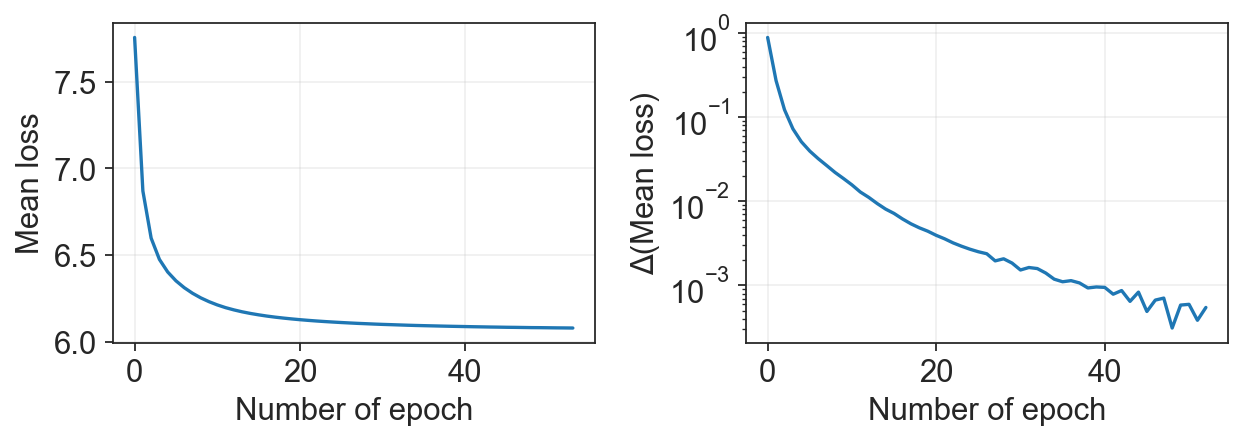

In [9]:
c2v.pl.loss_history(clones)

**What to look for:** the loss (left) flattens out, and its change per epoch (right, log scale) keeps decreasing. If the loss were still dropping steeply at the end, you would increase `max_iter`.

## Step 5: Explore clones like cells

The embedding is stored in `clones.obsm["clone2vec"]`. From here on, `clones` behaves like any single-cell object, and the usual `scanpy` workflow applies: kNN graph, UMAP, clustering. Each dot on the plots below is a clone.

In [10]:
sc.pp.neighbors(clones, use_rep="clone2vec")

computing neighbors
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:03)


In [11]:
sc.tl.umap(clones)

computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:00:11)


A first sanity check: colour the clonal UMAP by fate composition. The embedding was built without cell type labels, so if clones with similar fates end up together, the embedding has learned something real.

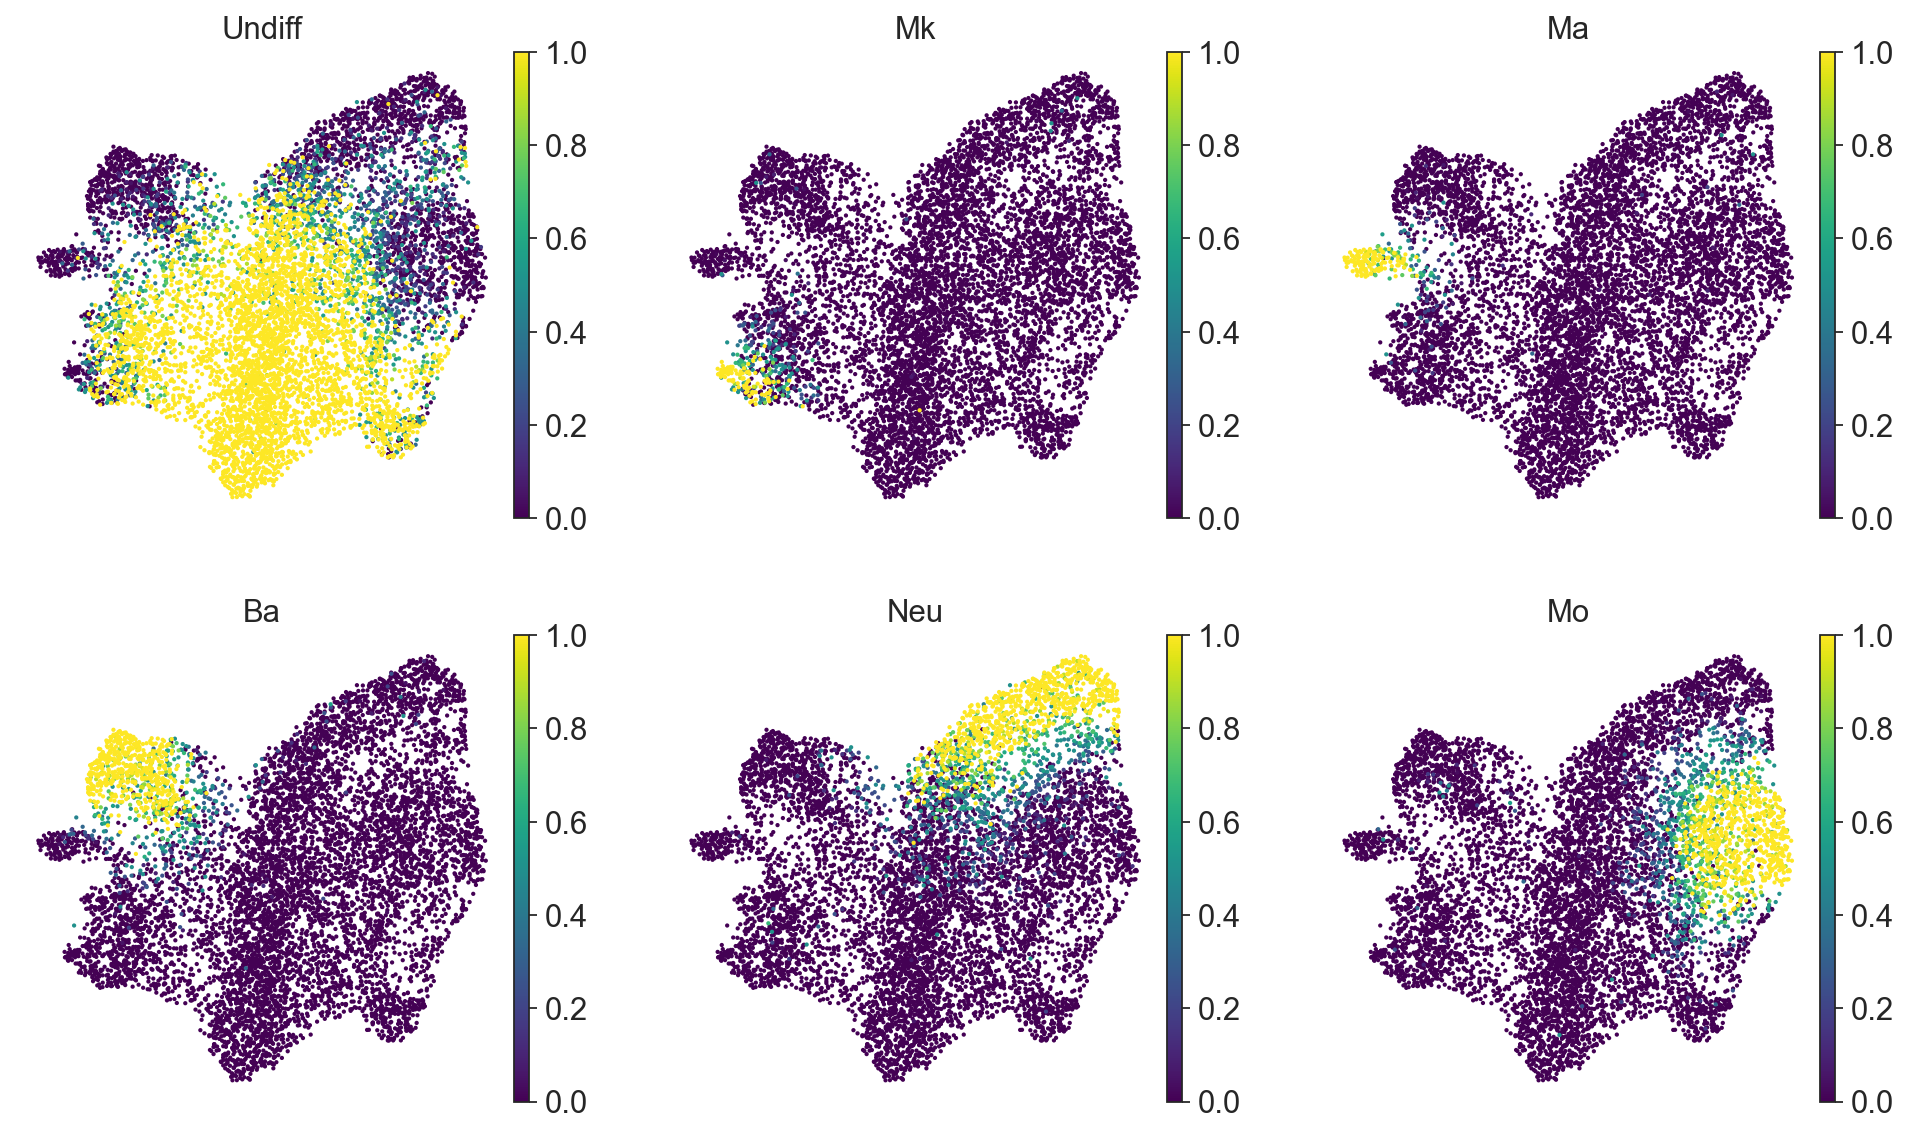

In [12]:
sc.pl.umap(
    clones,
    color=["Undiff", "Mk", "Ma", "Ba", "Neu", "Mo"],
    frameon=False,
    cmap="viridis",
    ncols=3,
)

**What to look for:** each fate occupies its own region of the clonal map. Clones made mostly of undifferentiated cells fill the centre. Monocyte (Mo) and neutrophil (Neu) clones sit next to each other, with mixed clones between them. Megakaryocyte (Mk), mast cell (Ma) and basophil (Ba) clones form their own corners.

Now let's group clones into clonal clusters with Leiden on the clone2vec kNN graph.

In [13]:
sc.tl.leiden(
    clones,
    resolution=1,
    flavor="igraph",
    n_iterations=2,
)

running Leiden clustering
    finished: found 13 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:00:00)


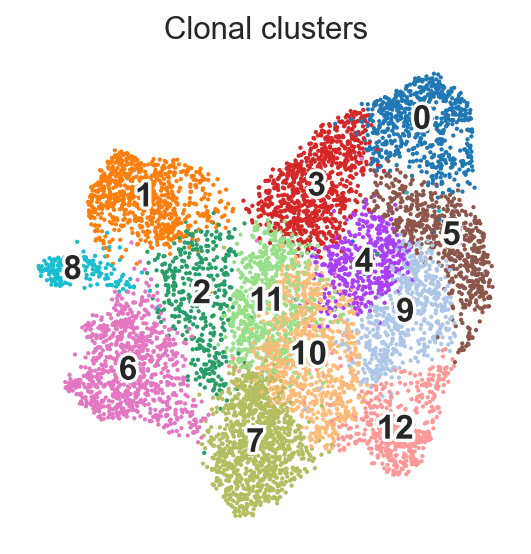

In [14]:
sc.pl.umap(
    clones,
    color="leiden",
    frameon=False,
    title="Clonal clusters",
    legend_loc="on data",
    legend_fontsize=15,
    legend_fontoutline=3
)

The composition of each cluster summarizes what its clones make. On the dot plot, **dot size** is the fraction of clones in the cluster that contain a fate, and **colour** is the average share of that fate within those clones.

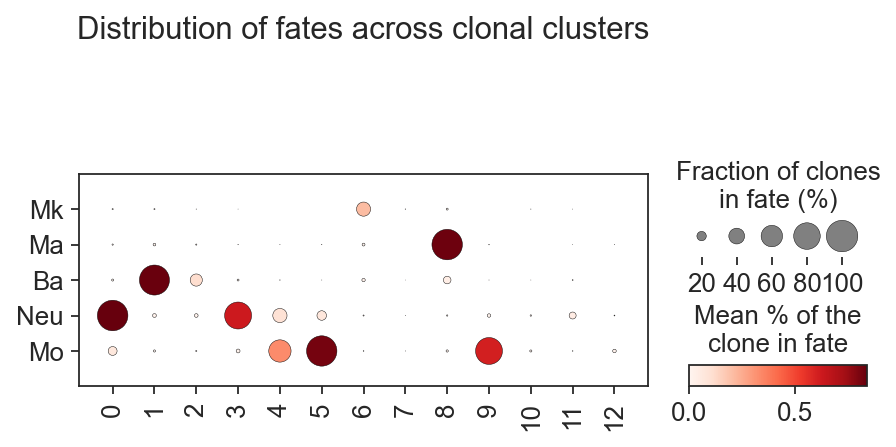

In [15]:
sc.pl.dotplot(
    clones,
    var_names=["Mk", "Ma", "Ba", "Neu", "Mo"],
    groupby="leiden",
    colorbar_title="Mean % of the\nclone in fate",
    cmap="Reds",
    swap_axes=True,
    size_title="Fraction of clones\nin fate (%)",
    title="Distribution of fates across clonal clusters",
    dot_max=1,
)

**What to look for:** several clusters are clearly fate-restricted, e.g. cluster 0 (neutrophils), 1 (basophils), 5 and 9 (monocytes), 6 (megakaryocytes) and 8 (mast cells). Clusters 7, 10, 11 and 12, however, show almost no mature fate: their clones consist mostly of undifferentiated cells.

clone2vec still separates them. They differ by *where in the undifferentiated region* their cells sit, a difference that cell type labels cannot see. The next step shows where that is.

## Step 6: Back to the cells

Clonal clusters become much more informative once we look at them from the cells' point of view. `c2v.pp.transfer_annotation` copies a clone-level column to every cell of the clone, as `adata.obs["c2v_leiden"]`.

In [16]:
c2v.pp.transfer_annotation(adata, clones, annotation_obs_clones="leiden")

transferring annotations between cell and clone objects
    finished (0:00:00): added to clonal AnnData
     .obs['c2v_leiden'] categorical labels


Now we plot where the cells of selected clonal clusters sit on the expression map: as a density (KDE) and as points.

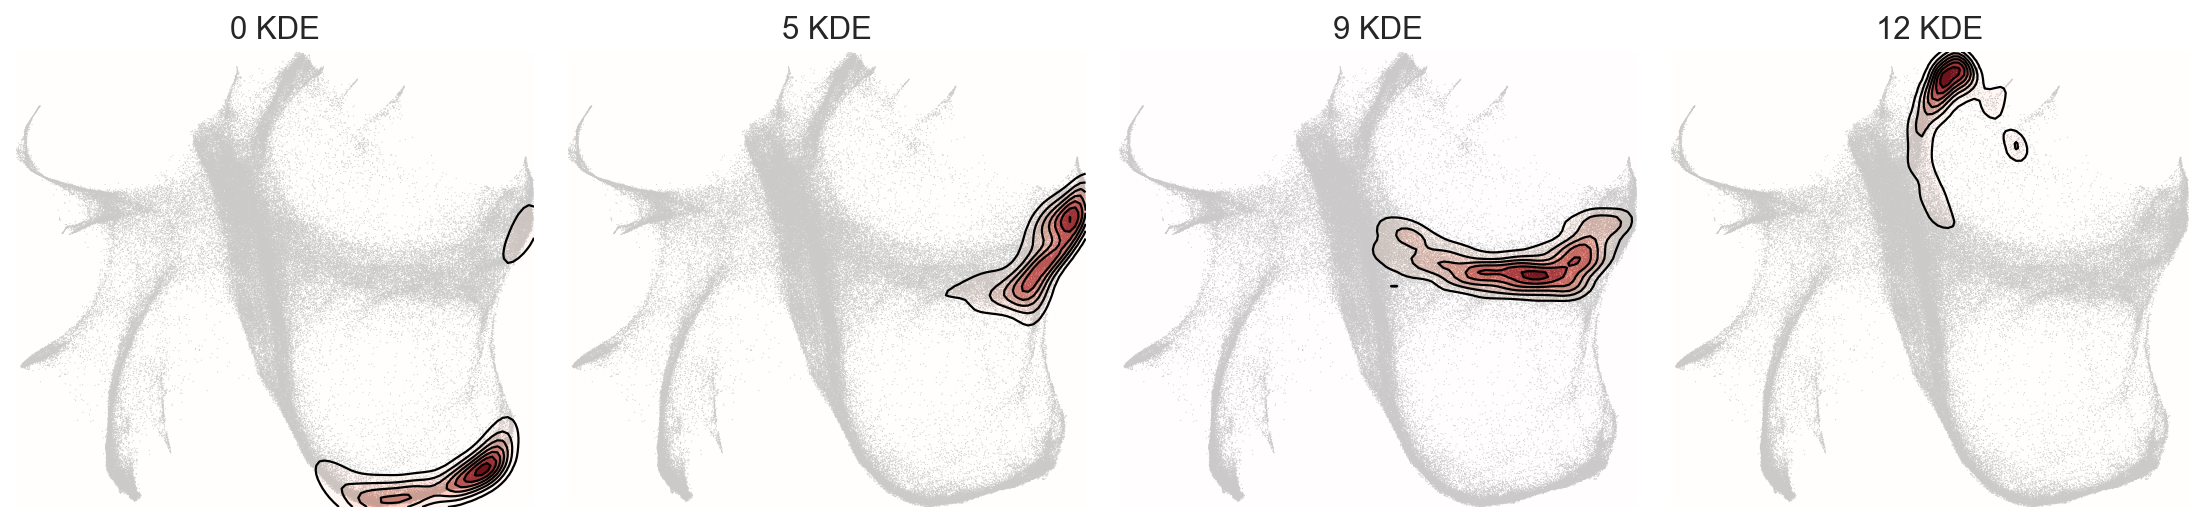

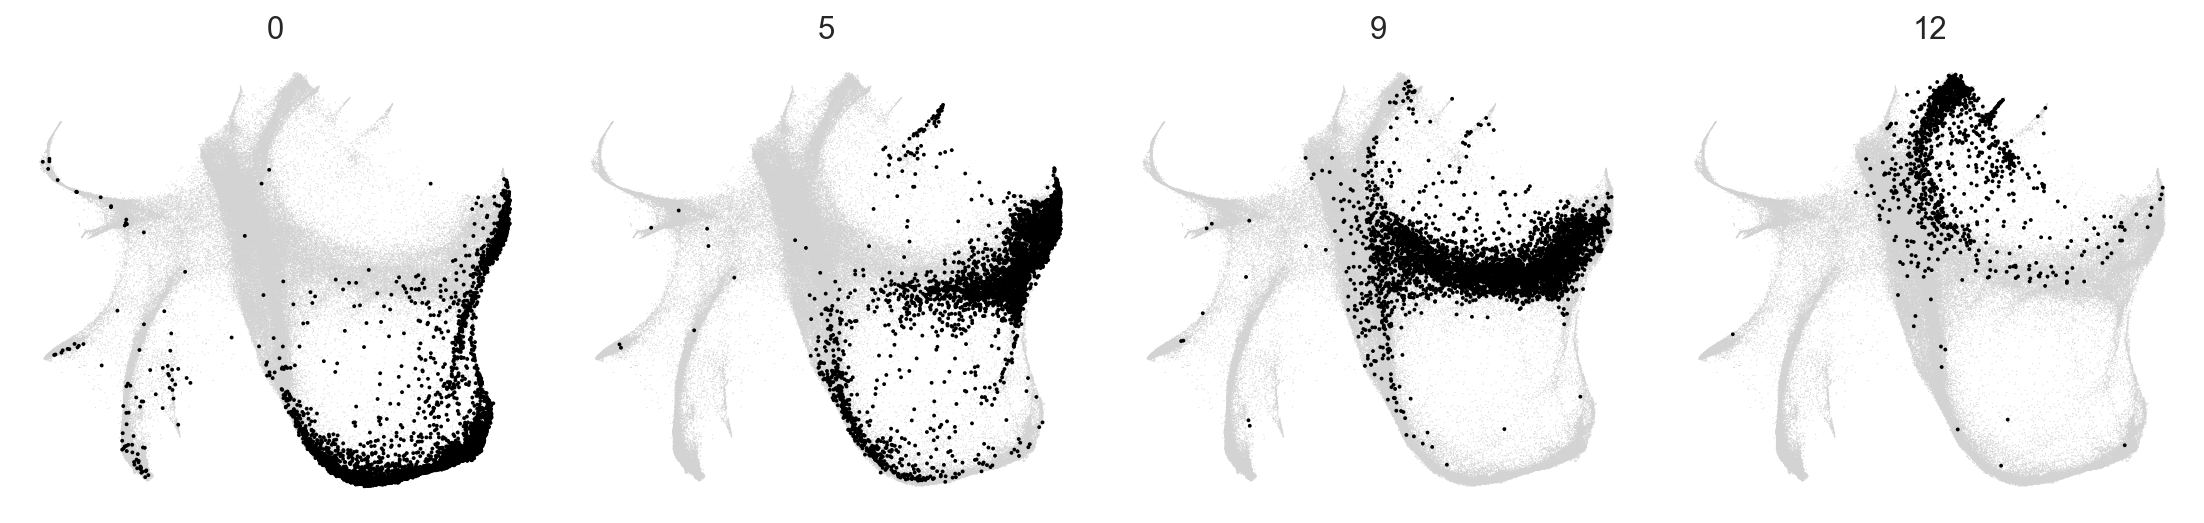

In [17]:
selected_clusters = ["0", "5", "9", "12"]

c2v.pl.group_kde(adata, groupby="c2v_leiden", basis="X_spring", groups=selected_clusters)
c2v.pl.group_scatter(adata, groupby="c2v_leiden", basis="X_spring", groups=selected_clusters, s=12)

**What to look for:** clusters 0 and 5 sit at the ends of the neutrophil and monocyte branches. Cluster 9 covers the path from undifferentiated cells towards monocytes. Cluster 12 occupies a specific upper part of the undifferentiated region, next to the lymphoid and dendritic branches.

The expression map alone shows the undifferentiated region as one continuous cloud. The clonal clusters split it into parts that lead to different outcomes.

To explore both maps together, `c2v.pl.clones2cells()` opens an interactive widget: select clones on the clonal map and see their cells on the expression map. It works in Jupyter and Google Colab but is not shown in the HTML version of this tutorial.

In [3]:
c2v.pl.clones2cells(
    adata=adata,
    clones=clones,
    cells_basis="X_spring",
    s_cells_bg=2,
    s_cells_selected=6,
    s_clones=8,
    height=450,
    cells_color="Cell type annotation short",
    keep_color=False,
    clones_color="leiden",
)

GridBox(children=(VBox(children=(HTML(value='<b style="display: flex; justify-content: center; margin: 0 0 0 3…

## Step 7: Do sister clones behave alike?

Recall that each clonal unit is a `time point : well : barcode` combination. The same barcode can therefore appear several times in the clonal map: at different time points, and in different wells. This lets us ask two questions about how much of a clone's behaviour is inherited.

First, let's see where clonal units of each time point sit.

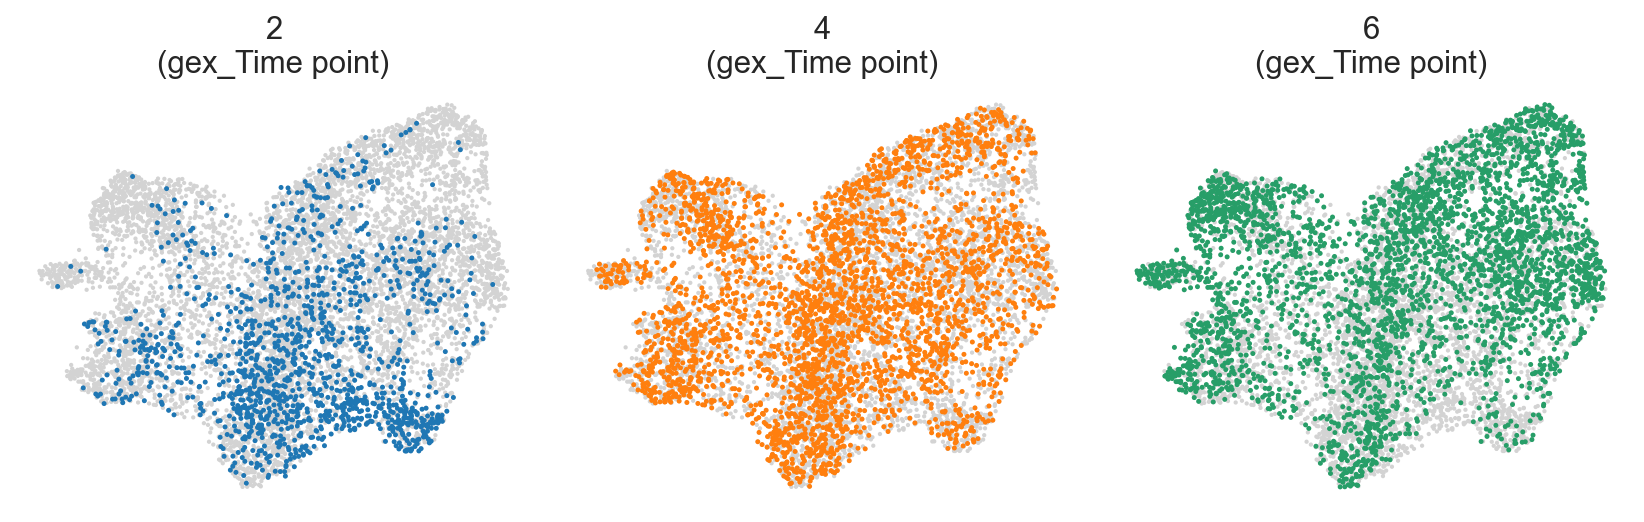

In [31]:
c2v.pl.group_scatter(
    clones,
    groupby="gex_Time point",
    basis="X_umap",
    groups=[2, 4, 6],
    s=20,
    kwargs_group={
        "color": "gex_Time point",
        "legend_loc": None,
    },
)

Day-2 units are concentrated in the lower central part of the map, where mostly undifferentiated clones sit. Day-4 and day-6 units spread out over the fate-restricted regions as their cells mature. The clonal map thus also reflects time.

### Question 1: does a clone's early position predict its later behaviour?

We connect every pair of units that share the same well and barcode, with an arrow from the earlier time point to the later one. Each arrow is one clone observed twice.

In [20]:
clones.obs["well:clone"] = (
    clones.obs["gex_Well"].astype(str) + ":" +
    clones.obs["gex_Clone"].astype(str)
)

c2v.utils.connect_clones(clones, groupby="well:clone", orient_col="gex_Time point",
                        orient_rule="increase")

connecting clones: 
    using .obs['well:clone'] to group clones
    finished (0:00:01): added
     .obsp['connected'] with graph of connected clones


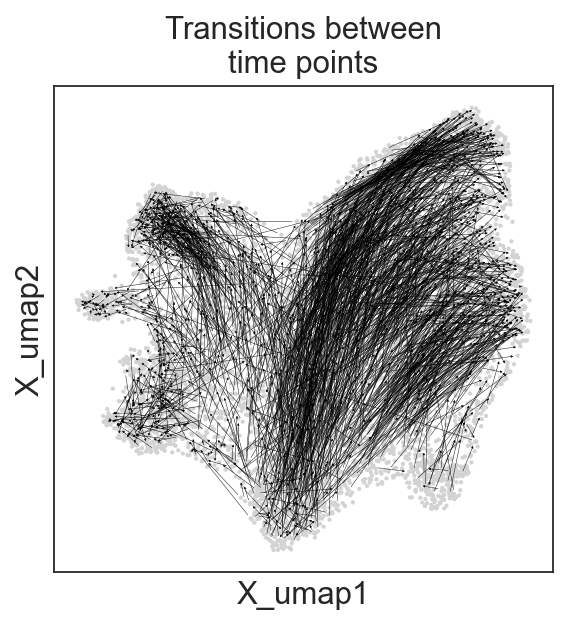

In [21]:
c2v.pl.graph(clones, graph_key="connected", oriented=True, linewidth=0.2,
            title="Transitions between\ntime points")

To summarize thousands of arrows, `c2v.tl.group_connectivity` counts arrows between every pair of clonal clusters and divides by the number expected by chance (`observed / expected`). Values above 1 mean that the clusters are linked more often than random.

In the heatmap, **rows** are clusters of the earlier sample and **columns** clusters of the later sample. Colours are capped at 1–5.

In [22]:
c2v.tl.group_connectivity(clones, groupby="leiden", graph_key="connected", directed=True)

computing groups connectivity matrix
    finished (0:00:00): added
     .uns['group_connectivity']['connectivity'] groups connectivity matrix
     .uns['group_connectivity']['label_names'] label names


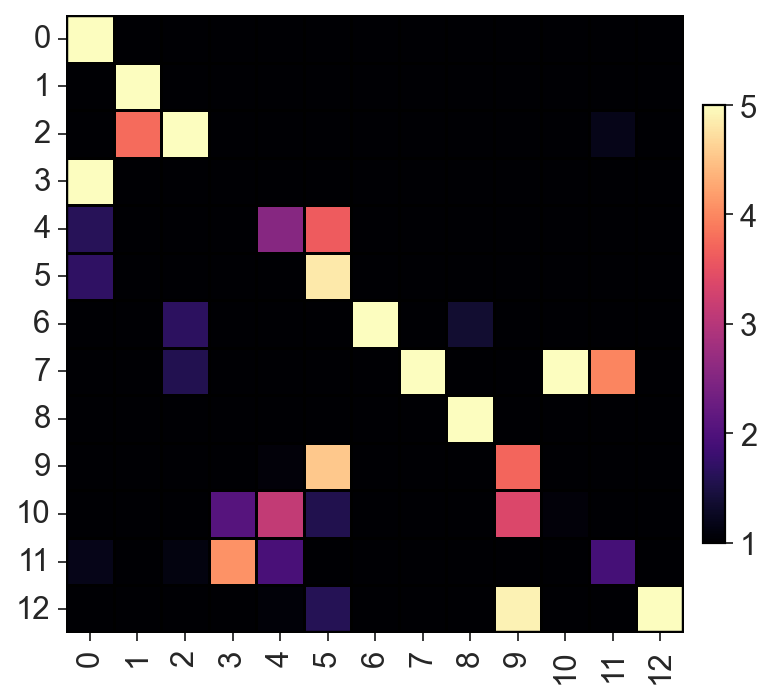

In [23]:
c2v.pl.heatmap(c2v.utils.get_connectivity_matrix(clones), vmin=1, vmax=5,
              cmap="magma", sort_columns=False)

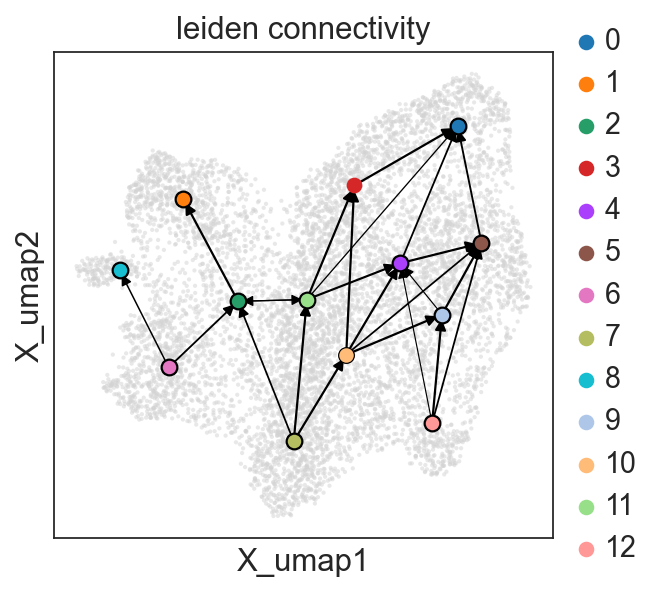

In [24]:
c2v.pl.group_connectivity(clones, linewidth=0.5)

**What to look for:** arrows run from the mostly undifferentiated clusters towards fate-restricted ones, in a consistent way. For example, cluster 12 leads to 9 and then to 5 (the monocyte path), cluster 3 leads to 0 (the neutrophil path), and cluster 2 leads to 1 (basophils). Where a clone sits early on predicts where it goes later.

### Question 2: do sisters in different wells behave alike?

Now we connect units that share the barcode and the time point but come from **different wells**. These are sister populations that grew apart, in separate wells, so the edges are undirected.

In [25]:
clones.obs["time:clone"] = (
    clones.obs["gex_Time point"].astype(str) + ":" +
    clones.obs["gex_Clone"].astype(str)
)

c2v.utils.connect_clones(clones, groupby="time:clone")

connecting clones: 
    using .obs['time:clone'] to group clones
    finished (0:00:00): added
     .obsp['connected'] with graph of connected clones


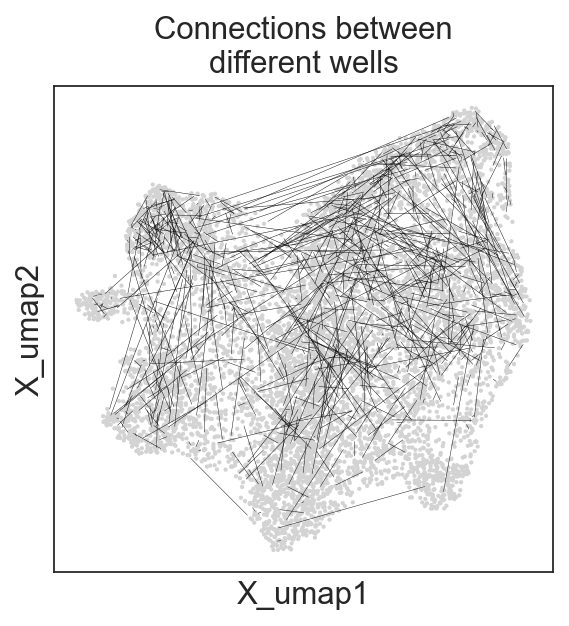

In [26]:
c2v.pl.graph(clones, graph_key="connected", oriented=False, linewidth=0.2,
            title="Connections between\ndifferent wells")

In [27]:
c2v.tl.group_connectivity(clones, groupby="leiden", graph_key="connected", directed=False)

computing groups connectivity matrix
    finished (0:00:00): added
     .uns['group_connectivity']['connectivity'] groups connectivity matrix
     .uns['group_connectivity']['label_names'] label names


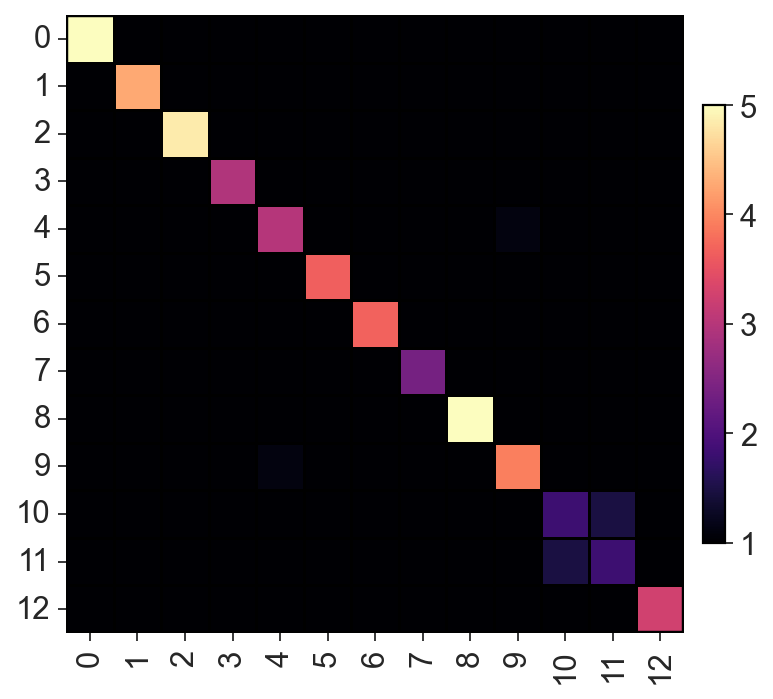

In [28]:
c2v.pl.heatmap(c2v.utils.get_connectivity_matrix(clones), vmin=1, vmax=5,
              cmap="magma", sort_columns=False)

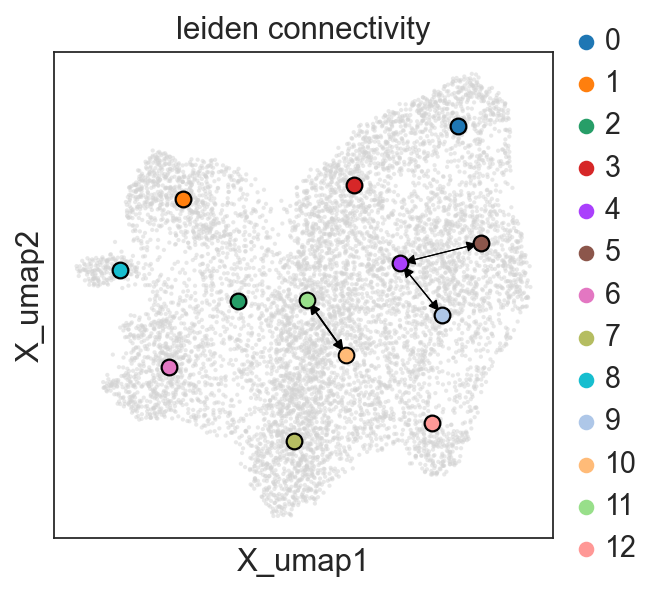

In [29]:
c2v.pl.group_connectivity(clones, linewidth=0.5)

**What to look for:** the connectivity matrix is almost perfectly diagonal. Sister populations raised in different wells land in the **same** clonal cluster. Their environment differed but their history did not, so in this system a clone's fate bias is largely inherited, in line with the conclusions of Weinreb et al.

The few off-diagonal links (10 ↔ 11, 4 ↔ 5 and 4 ↔ 9) connect clusters that are neighbours on the clonal map anyway.

## Save the results

We save both objects. The [Fast clonal embeddings](Fast_clonal_embeddings.ipynb) notebook reuses the clonal one.

In [30]:
clones.write_h5ad("Weinreb_clones.h5ad")
adata.write_h5ad("Weinreb_cells.h5ad")

## Summary

* A clone is described by **which clones its cells neighbour** in expression space, not by cell type labels.
* clone2vec turns these neighbour counts into a clonal embedding that handles small and uneven clones gracefully.
* The embedding is analysed like any single-cell object, and clonal clusters projected back to the cells reveal structure that the expression map alone does not show.

**Where to go next:** [Gene expression associations](Gene_expression_associations.ipynb) asks which genes go with these clonal behaviours, and [Non-randomness of the clonal embedding](Structure_test.ipynb) checks whether the structure could arise by chance.